# Cross-venue thesis walkthrough — synthetic only

This notebook loads a committed **five-minute invented BBO tape** (6,002 rows).
It is not anonymized market data. The generator deliberately inserts delayed,
directional follower responses; detecting them is not an alpha discovery.

Run all cells locally or in Colab. Data and the exact cost-bridge source are
embedded as checksummed compressed fallbacks, so a downloaded notebook does not
need a repository checkout. NumPy and Matplotlib are used; the setup cell installs
them only if missing. No exchange access, account, raw study archive or order is used.

The active study is unchanged and outcome-gated. All confidence bands below are
**toy episode-bootstrap intervals**, not evidence of market predictability.


In [1]:
import base64
import csv
import gzip
import hashlib
import importlib.util
import io
import pathlib
import subprocess
import sys
import tempfile
from decimal import Decimal
for package in ("numpy", "matplotlib"):
    if importlib.util.find_spec(package) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", package], check=True)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
print("NumPy", np.__version__, "· all inputs are synthetic")


NumPy 2.5.4 · all inputs are synthetic


In [3]:
DATA_SHA256 = 'bd77b504ea8e9f83e3fdc243fcc880a77a0c24650297a77bad631af57eed2c10'
TOOL_SHA256 = '8c9292e622deeada0a74ebfcfcedb688d933402e35eac6f1e1cee84d8e1954be'
DATA_GZIP_BASE64 = '...'
TOOL_GZIP_BASE64 = 'H4sIAAAAAAACA6VZW3PbNhZ+16/AsA+hXIq1PW0e0qgz6Tad7Us3s8nuPng9HIiEJNS8lSBtq4n/+37nAKBASVayrcZjiSTOBQffuTKKorePbalz3S+kMUPV9rqphXrEdd6YXqy7pu616r4XdSN62Sqh63boTSKU6XUle2VE0+GvUJ1JZ7MPW7dCVLK7a/CtjZBlp2SxE7XqRbMGd5UPvVyVSqi673ZC1oXQvXFXa6XS2ZuyFG2ncwVJpIjhRb8PEtpAHyNWqmwehOwgriwH03ey1/cqgZq9yGWpV3SjqdNZFEUz7KISWbYe+qFTWSZ01TZdD5ZYzcvMbObvdZtWdkZZmgIbxDaVp/DXiaD/fzS1X6dyGKP0y36yl4n4pb6HLsU/WmXVSUTZQLscRlWPvZe5lWYLjf3lb6apLdtW9vTAs32HS7/IDKu2a2AfqP7ju/di6YXGV5f4zGezWaHWXrEYagxq/mom8IGR7Q/6dMoMZR+Qw5Ru9ZwXqcdctf3RToQ09ChgJLVR4t9E+bbrmi6O1rrWvdrbhmHRqd8H3akimgveIngwC73mo7PqpNpkljqe/wUJM7tBHHrtGDurrDpdbFR8kXiUZqsWQDO6UMuobOpNlFgwZozBZfSSbIqbDoC7bNXnyyi9vLyKklE/MhYTAcHEcBl9R3zgSyfumJZ8wt5Mrw+48IJSt63cODoSLot7OJnK+HHV3AeP1kNd6HqTkav4u85yEbm4zMkrzNbtXGC56kAFL1vDf6x3VXAPWZY7OhO4FNyJNWH/E73qKnJwYvmedTd2J6Lo9LpnBl5ldstOleySokfgQFTY7toG370G/sW26TS8h7lVukjFzwo+TWT5Fh6oCkFRSOZbAc2hFGtJAAHyZInldr8cXHBsm1oVzItV1bWACTjScEDZk1F0woni0HdjfPLBqZW6cAQccFJvPQ9PQgdjFPxjj5LIYCt9dBalTFghRiFoCaKjiOnorAUSG+uAr36X7EG0Bw+wyTZP2MaJtfl47PDeSrZx4aNOPCozgXeA6CmSkylup5jdI/MAt8kxTp/B6DE+XWyBVVkd8XopLskq2D//PmfOtjGagWUPyzIIssPuMAJAiqx38aN4bYU8ih+WgmLmmi/oOL/U5PPz4YhBDE3YL9ZQjHPLePaXafqaozPh0ynnV+EMrTzxjbgWX7NQfLFUv4txrdMf6suViZ1x5/72Yn+c57RlX9knfQ7nCp5HzmqGlrIMroqmkrp2yj7ofjvJYPGc8oC72AtzN1JsKMfGvr0cnxQ4F7/fMWGN3rVcCutYQpXQdnE13yMZ3rl0h30hQPN1wAs3KtwYtz2HEWGJPTUEEIMptE6bZaxbKtRFdJ7w+XrEnAtcxC2aTz2jQn7RRNNB0SucQqjfeHSs2JTQbmrJGl4c8ppNUwsFcdohlpOvXIwWGfd+SsIRVSD3YkT8AeWma4wBRbgNSx0H5Aurwd4Wo6tTujnU0gesqSSqC5dO3uJwo4uDLSwmEkIeFFjAh7h9I+JA8Bw/QnlfiV+xhlZT/lijiqCilYHvssGClVgQK4eHhKPFWj/CJ4L8QB9TNi2ZNj489Klh52cOt9+iPtk2JWG8Ahe/m28s86Ba42LmY2TRWWQOjxnh8RUhCClpfzq4tb+YlBj8idjk9mnW1mU2mKIHDd8mRmNWcA+mR3OC4Zg4PEF4dOA4yQNuTXicJ1iSKboGa/pOt54GN5PDRxRTX3nLnWAki0LbQsBmJ5+LyG57k58gXAESd5m6V3VmDUBLg8wKBuP5PbkK86FDYZoVqmpirHJZA7/S6g4IidFigJVZfugGm3KgSnO3/Fki7FlXCgPzEgceJG/IGwvSKMzj9MDWpOHZWQ2p8jza2uTIxnVPvM7kqpadblj8SBn1erPt2YBY/DE6qAlYg+vIgzCsDejR5Wkd3PGcqBwc0QFwxgdPe3bRAxLIWb2eVyv97lm9/rJaBcrgHRz1T1osvX5et7PqXT+nXnrl9bPn3DUPdMQ3t7YcodKUUvH5IpeW1ZL6YNucY/WIlxTIr0zYuHmKynJl1V7Sv6vL6GDZpCV1bVrgasvKdWn0LxEXF4Gb0CVrMz/miD2msm1VXcQfuR6HJSyLyOtNsYN3FD3n5NWZg7CHsVcGy0MP/mTt9DkGHCntrgkrd1CSuvE5W+8uEfdkQN8iWys/fY5n2HdZIGyHrig5iuSlklQnU31k2d6cCKq34gcUzlyRReh/Mk/15Btsd1ywbL5VlcwIktg2JFyRgXe1lY9rG+8idQ/b10g6/a5lRfa2yoyqudZCTAuQjxVZs84GDnJ+CpPWzUPsBzEpns1TbRrYqpKoTAPiDYf7qmIX3E9OUqib32U44Xbo4xtaRqjs1P2CZ0B08fe3b36KbhNB9SyH63lqyDJH/BHWofErsWqaMv6sDNPLfjD0a7FApZ0jSqDKPiknFNSDeWa28vq7lxDl5kapvRHTeCjOMrTKKsvmqY0wu14BJfN0qx4LvVFmahhgqEWbrr6UJzUAGblJHFG3SaeceR7ptq/K6MvkkmMBZzRQNBkRQPIljGHniISB3t0h18VP+gro86GjBApSAyzm28xrQ2D6p6KWxbkKP/6ephFKGtRuJtcg1GudC49C17LRUJLqtmB6yBOJoZb3Upc0r0xDRJYaeJLe22+iN4Rh5WYIYeloe0I3xezsDGGte+quKChCrwHuJKxNghlneibyRz8Hs5teEJzAwk5MD0elJFNa5XiM+/ugyAsL1fbbBJb5zRWsUCaXrcypha4aJK6zCrylHnec+PDIqIAw7h4V3AcKlTuvmGttSTG0Uv3Ct1EufQnKXBUM95ktHw19xqzD5uXduYFRK3fEUFBIKoZSEZWu1wq4Kc5K+ZV41WsHDY1GtrunoQoJJL5ds5IrXWqa1Lzfyg6lP4OFzLfumj9UvTD9UOygCA1OJXHpnAKIQYgCpMCtTb5UHKLIH50ppdkvfMiWj9xh0520QHQ0sY20CZSCcv3yOkG7UjYPcMjalY5ogqP/+m69RF/DqT36CoFXsu0U9tZUOjdUm9vBf5ioKCAdGid67wN4sFIEYToVsJlD7/hWIAnfFgSvCE5K+CV8Y7B/X6BrBtXpFwbjywJj53pusokq3xzxl7V3gAkvIDjhFw8WMws/KCSudqBpQea7VsLY6Q18Eu+paPokrFd4UOL6uI+kvu4Td6CcZhcU5cO7/3r/04dEXFIhL3788Dfc/ZEakAU1INN3K47qhDaLxUIE/1898xXtiz4EWI6YiLPBHMf28Lh5M6lNbscVjDFfWq0h+SMtfkG11YvbJzFeO4uE906WWXZBdNo919FHPzMibW5eHNUqL27nr9Jv1yzk3FJqI3nty/X/I+9zneBe/MQFvyYfjJKxxHo+e92eABdCLYLkzp4QhT47hPCAhmbutZcU+baBXwp+G6Y2Ox4QIq6vDGIYlrrK8VjAO/embT/Pn04/7VAfDrH2Y/qh9mmSkgoFfdbqmLUft9us2DcLmnLZKFHbhOBSs9jwy8TOJm/w38p6w6HydKSsimmcpLiX/tboOmajT0PhEbWrVQL6P1vp2DGoFcO1Ho6Fe+Y2JfKjiqp9vkBiR2y5meLhK2lNdX5HI4P5fJoyRlnnc8a4bJ82pqY5fD+GViDjjWcZz2OzjA4kyyIbFrgwpgmnf1Gavuk2A6Xad/wkRhGQw8Uoki6zrGhyWDOgTBGgM+lIYlS/2A5cgxqBJR1BMk7vbRVshyHdhkzqOPAX8YD9ph1IMHWhxymNXqzsDokc8ek/XdMr8bFUtUumNy8o4sFvn8Z8GL4IJ+cyXFa4/IbWQ4bZbD77Hw8lmwhDHwAA'
local_data = pathlib.Path("notebooks/data/synthetic_5min.csv")
data = local_data.read_bytes() if local_data.exists() else gzip.decompress(base64.b64decode(DATA_GZIP_BASE64))
assert hashlib.sha256(data).hexdigest() == DATA_SHA256
local_tool = pathlib.Path("research/trading_decision.py")
tool = local_tool.read_bytes() if local_tool.exists() else gzip.decompress(base64.b64decode(TOOL_GZIP_BASE64))
assert hashlib.sha256(tool).hexdigest() == TOOL_SHA256
scratch = tempfile.TemporaryDirectory()
module_path = pathlib.Path(scratch.name)/"walkthrough_bridge.py"
module_path.write_bytes(tool)
spec = importlib.util.spec_from_file_location("walkthrough_bridge", module_path)
cost = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cost)
rows = list(csv.DictReader(io.StringIO(data.decode())))
assert len(rows) == 6002
print("Rows:", len(rows), "· duration:", int(rows[-1]["local_ts"])/1000, "seconds")
print("Fixture SHA-256:", DATA_SHA256)
print("Cost tool SHA-256:", TOOL_SHA256)


Rows: 6002 · duration: 300.0 seconds
Fixture SHA-256: bd77b504ea8e9f83e3fdc243fcc880a77a0c24650297a77bad631af57eed2c10
Cost tool SHA-256: 8c9292e622deeada0a74ebfcfcedb688d933402e35eac6f1e1cee84d8e1954be


## Receive-time event curve

The 30 signal times and directions are fixed by the toy generator, never selected
from profitable outcomes. Use only quotes at or before each query timestamp.
Negative offsets show pre-signal behavior. A 100 ms sample grid cannot establish
submillisecond order or physical venue propagation time.


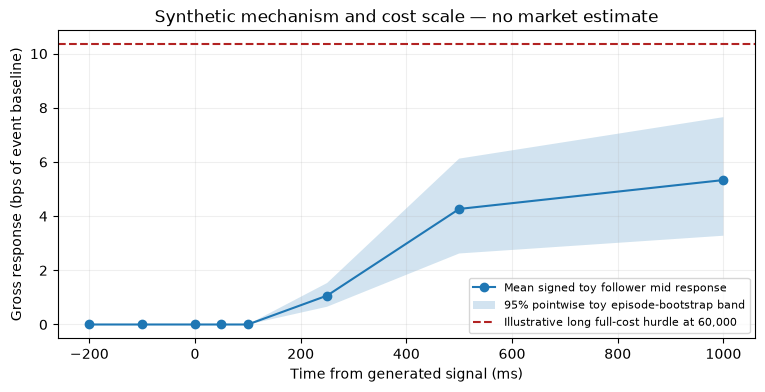

Toy episodes: 30 · illustrative gross hurdle: 10.3385 bps


In [4]:
follower = [r for r in rows if r["venue"] == "okx"]
times = np.array([int(r["local_ts"]) for r in follower])
mids = np.array([(float(r["bid"])+float(r["ask"]))/2 for r in follower])
offsets = np.array([-200, -100, 0, 50, 100, 250, 500, 1000])
curves = []
for episode in range(30):
    signal = episode*10000+2000
    direction = 1 if episode % 2 == 0 else -1
    query = signal+offsets
    index = np.searchsorted(times, query, side="right")-1
    assert np.all(index >= 0) and np.all(query <= times[-1])
    assert np.all(query-times[index] <= 100)
    baseline = mids[np.searchsorted(times, signal, side="right")-1]
    curves.append(direction*(mids[index]/baseline-1)*10000)
curves = np.array(curves)
rng = np.random.default_rng(0)
indices = rng.integers(0, len(curves), size=(2000, len(curves)))
bootstrap = curves[indices].mean(axis=1)
lower, upper = np.quantile(bootstrap, [.025, .975], axis=0)
mean = curves.mean(axis=0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(offsets, mean, marker="o", label="Mean signed toy follower mid response")
ax.fill_between(offsets, lower, upper, alpha=.2, label="95% pointwise toy episode-bootstrap band")
# Exact long break-even at an illustrative 60,000 initial mid; both $1 half-spreads and both 5bps fees.
hurdle_mid = Decimal("60001")*(1+Decimal(".0005"))/(1-Decimal(".0005"))+1
hurdle_bps = float((hurdle_mid/Decimal("60000")-1)*10000)
ax.axhline(hurdle_bps, color="firebrick", ls="--", label="Illustrative long full-cost hurdle at 60,000")
ax.set(xlabel="Time from generated signal (ms)", ylabel="Gross response (bps of event baseline)",
       title="Synthetic mechanism and cost scale — no market estimate")
ax.legend(fontsize=8)
ax.grid(alpha=.2)
plt.show()
print("Toy episodes:", len(curves), "· illustrative gross hurdle:", round(hurdle_bps, 4), "bps")


These bands resample invented episodes as if independent and are pointwise,
unadjusted across horizons. One five-minute tape supplies no independent market
dates. Missing and unavailable observations cannot be turned into zero returns.
The long hurdle is a stated price/cost example, not a fitted trading rule or a
common exact hurdle for every side, episode, size or execution path.

## Exact entry-net-to-exit cash bridge

The input +2 bps below has **already paid entry spread and entry fee**. Add the
exit and its actual-notional fee; do not charge entry fees twice. This arithmetic
example is separate from the gross response curve above.


implied_horizon_mid 60042.0000
entry_fee_usdt 0.030
exit_fee_usdt 0.0300210
net_roundtrip_usdt -0.0180210
break_even_entry_net_markout_bps 5.005002501250625312656328164082041020510


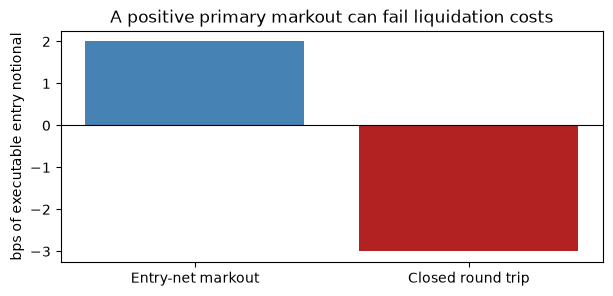

In [5]:
bridge = cost.bridge(markout_bps="2", entry_price="60000", quantity_btc=".001",
                     entry_fee_bps="5", exit_fee_bps="5", exit_spread_bps="0")
assert bridge["net_roundtrip_usdt"] == Decimal("-.018021")
for name in ("implied_horizon_mid", "entry_fee_usdt", "exit_fee_usdt", "net_roundtrip_usdt",
             "break_even_entry_net_markout_bps"):
    print(name, bridge[name])
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(["Entry-net markout", "Closed round trip"], [2, float(bridge["net_roundtrip_bps"])],
       color=["steelblue", "firebrick"])
ax.axhline(0, color="black", lw=.8)
ax.set(ylabel="bps of executable entry notional", title="A positive primary markout can fail liquidation costs")
plt.show()


## What would make this empirical?

A verified released dataset, enough independent dates, chronological holdout,
fixed conditions, valid dependence-aware inference and actual execution inputs.
Continuous OFI, impact sensitivity, multiplicity/DSR/PBO and columnar joins are
separate tools; they do not make these synthetic returns measured alpha.
The notebook sends no orders. A negative or inconclusive scientific result remains useful.
